In [1]:
import os
CUDA_LAUNCH_BLOCKING=1
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:64,garbage_collection_threshold:0.6"

import sys
import numpy as np
import pandas as pd
from pathlib import Path
import logging
import json
import muon as mu

import torch
import torch.nn as nn
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER")
sys.path.append(str(PROJECT_DIR))

import models.tf_to_dna as tf_to_dna_module
from scripts.train_tf_to_dna_model import TFPeakEdgeDataset
from torch.utils.data import ConcatDataset, DataLoader

DATA_DIR = PROJECT_DIR.parent / "data"
CHKPT_DIR = PROJECT_DIR / "checkpoints"

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")

2026-10-14 14:30:49.510096: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/muon/_core/preproc.py:32: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


### Plotting and Helper Functions

In [271]:
def detach(tensor):
    if isinstance(tensor, torch.Tensor):
        return tensor.detach().cpu().numpy()
    else:
        return tensor

def unmask(tensor, mask):
    if isinstance(tensor, torch.Tensor) and isinstance(mask, torch.Tensor):
        return tensor[mask == 1]
    else:
        raise ValueError("Both tensor and mask must be torch.Tensor instances.")

def plot_single_row_heatmap(values, col_values, title):
    fig, ax = plt.subplots(figsize=(6, 0.5))

    if isinstance(values, torch.Tensor):
        values_plotting = values.detach().cpu().numpy()
    else:
        values_plotting = torch.tensor(values).unsqueeze(1).numpy()

    im = ax.imshow(
        values_plotting.T,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
    )

    tick_positions = np.linspace(0, len(col_values) - 1, 9, dtype=int)
    ax.set_xticks(tick_positions)

    tick_labels = [f"{col_values[i]:.1f}" for i in tick_positions]
    ax.set_xlabel("Expression Input", fontsize=14, labelpad=10)

    ax.set_xticklabels(tick_labels, fontsize=12)
    ax.set_yticklabels(["1"], fontsize=12)
    ax.set_title(title, fontsize=16, pad=10)
    # fig.colorbar(im, ax=ax, label="Projection output")
    ax.xaxis.set_label_position('top') 

    ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False, left=False, labelleft=False)

    plt.show()
    
    
def plot_single_column_heatmap(values, row_values, title):
    fig, ax = plt.subplots(figsize=(1, 8))

    if isinstance(values, torch.Tensor):
        values_plotting = values.detach().cpu().numpy()
    else:
        values_plotting = torch.tensor(values).unsqueeze(1).numpy()
        
    im = ax.imshow(
        values_plotting,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
    )

    tick_positions = np.linspace(0, len(row_values) - 1, 9, dtype=int)
    ax.set_yticks(tick_positions)

    tick_labels = [f"{row_values[i]:.1f}" for i in tick_positions]
    ax.set_ylabel("Projection dimension", fontsize=14, labelpad=10)

    ax.set_yticklabels(tick_labels, fontsize=12)
    ax.set_title(title, fontsize=16, pad=10)
    # fig.colorbar(im, ax=ax, label="Projection output")
    ax.xaxis.set_label_position('top') 

    ax.tick_params(top=False, labeltop=False, bottom=False, labelbottom=False, left=False, labelleft=False)

    plt.show()


def plot_projected_expression(
    projection_dict,
    keep_square=False,
    height=8,
    ncols=3,
    xlabel=None,
    ylabel=None,
    cmap="viridis",
):
    if not projection_dict:
        raise ValueError("projection_dict must not be empty")

    # Prepare matrices without modifying the original dictionary.
    prepared = []
    for title, (projected, inputs) in projection_dict.items():
        if projected.ndim == 3 and projected.shape[0] == 1:
            projected = projected.squeeze(0)

        if projected.ndim != 2:
            raise ValueError(
                f"{title}: expected a 2D projection or a singleton batch, "
                f"got shape {tuple(projected.shape)}"
            )

        if any(size == 0 for size in projected.shape):
            raise ValueError(f"{title}: projection dimensions must be nonzero")

        prepared.append((title, projected.T, inputs))

    # Number of subplot columns and rows
    if ncols < 1:
        raise ValueError("ncols must be positive")

    ncols = min(int(ncols), len(prepared))
    nrows = (len(prepared) + ncols - 1) // ncols

    # Physical cell dimensions, in inches
    cell_width = 0.15
    cell_height = 0.15

    # Margins and spacing, in inches
    left, right = 1.0, 0.3
    bottom, top = 0.8, 1.2
    hgap = 1.0
    vgap = 1.5  # Room for titles and x-axis labels between rows

    shapes = [matrix.shape for _, matrix, _ in prepared]

    # Each layout column/row accommodates its largest heatmap.
    column_widths = [
        max(
            shapes[i][1] * cell_width
            for i in range(col, len(prepared), ncols)
        )
        for col in range(ncols)
    ]

    row_heights = [
        max(
            shapes[i][0] * cell_height
            for i in range(row * ncols, min((row + 1) * ncols, len(prepared)))
        )
        for row in range(nrows)
    ]

    # Scale all heatmap cells uniformly to fit the total height limit.
    fixed_height = bottom + top + vgap * (nrows - 1)
    if height <= fixed_height:
        raise ValueError(
            f"height must exceed {fixed_height:.1f} inches "
            "to accommodate margins and spacing; increase height or ncols"
        )

    scale = min(1.0, (height - fixed_height) / sum(row_heights))
    
    title_fontsize = max(6, 16 * scale)
    label_fontsize = max(6, 14 * scale)
    tick_fontsize = max(5, 12 * scale)

    column_widths = [width * scale for width in column_widths]
    row_heights = [row_height * scale for row_height in row_heights]

    plot_widths = [cols * cell_width * scale for rows, cols in shapes]
    plot_heights = [rows * cell_height * scale for rows, cols in shapes]

    fig_width = left + sum(column_widths) + hgap * (ncols - 1) + right
    fig_height = fixed_height + sum(row_heights)

    fig = plt.figure(figsize=(fig_width, fig_height))
    axes = []

    row_top = fig_height - top

    for row in range(nrows):
        x = left

        for col in range(ncols):
            i = row * ncols + col
            if i >= len(prepared):
                break

            plot_width = plot_widths[i]
            plot_height = plot_heights[i]

            ax = fig.add_axes([
                x / fig_width,
                (row_top - plot_height) / fig_height,
                plot_width / fig_width,
                plot_height / fig_height,
            ])
            axes.append(ax)

            x += column_widths[col] + hgap

        row_top -= row_heights[row] + vgap

    for ax, (title, matrix, inputs), plot_height in zip(
        axes, prepared, plot_heights
    ):
        ax.imshow(
            matrix,
            aspect="equal" if keep_square else "auto",
            interpolation="nearest",
            cmap=cmap,
        )

        if inputs is not None and len(inputs) > 0:
            tick_positions = np.unique(
                np.linspace(0, len(inputs) - 1, 9, dtype=int)
            )
            ax.set_xticks(tick_positions)
            ax.set_xticklabels(
                [f"{inputs[j]:.1f}" for j in tick_positions],
                fontsize=tick_fontsize,
            )
            ax.set_xlabel(
                xlabel if xlabel is not None else "Expression Input",
                fontsize=label_fontsize,
                labelpad=10,
            )
            ax.tick_params(
                axis="x",
                top=True,
                labeltop=True,
                bottom=False,
                labelbottom=False,
            )
        else:
            ax.set_xticks([])
            if xlabel is not None:
                ax.set_xlabel(xlabel, fontsize=label_fontsize, labelpad=10)

        ax.tick_params(axis="y", labelsize=tick_fontsize)
        
        label = ylabel if ylabel is not None else "Projection size"

        # Remove existing newlines, then wrap only for short heatmaps.
        label = " ".join(label.split())

        if plot_height < 1.5:
            label = label.replace(" ", "\n")

        ax.set_ylabel(label, fontsize=label_fontsize, wrap=False)
                
        
        ax.set_title(title, fontsize=title_fontsize, pad=10)
        ax.xaxis.set_label_position("top")

    plt.show()

### Loading the TF-DNA binding model and inputs

In [2]:
def strip_compiled_prefix_from_state_dict(state_dict, prefix="_orig_mod."):
    """
    Remove torch.compile's _orig_mod prefix from state_dict keys.

    Examples:
        model._orig_mod.encoder.weight -> model.encoder.weight
        _orig_mod.encoder.weight       -> encoder.weight
    """
    cleaned = {}

    for key, value in state_dict.items():
        cleaned_key = key.replace(prefix, "")
        cleaned[cleaned_key] = value

    return cleaned

def load_tf_dna_model(
    tf_dna_model_path: Path,
    tf_embeddings_tensor: torch.Tensor,
    tf_mask_tensor: torch.Tensor,
    device: torch.device | None = None,
    model_module=None,
) -> tf_to_dna_module.LitTFPeakBindingModel:

    model_module = model_module or tf_to_dna_module

    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # -----------------------------
    # 1. Recreate base TF-DNA model uncompiled
    # -----------------------------
    base_model = tf_to_dna_module.TFPeakBindingModel(
        tf_embedding_dim=128,
        hidden_dim=128,
        dropout=0.3,
        num_layers=4,
        num_heads=4,
        dim_head=32,
    )

    # -----------------------------
    # 2. Load TF-DNA checkpoint
    # -----------------------------
    tf_dna_ckpt = torch.load(
        tf_dna_model_path,
        map_location="cpu",
        weights_only=False,
    )

    tf_dna_state_dict = tf_dna_ckpt["state_dict"]

    if any("._orig_mod." in key or key.startswith("_orig_mod.") for key in tf_dna_state_dict):
        logging.info("Detected compiled TF-DNA checkpoint. Stripping _orig_mod prefixes.")
        tf_dna_state_dict = strip_compiled_prefix_from_state_dict(tf_dna_state_dict)

    lit_tf_dna_model = tf_to_dna_module.LitTFPeakBindingModel(
        model=base_model,
        tf_embeddings_tensor=tf_embeddings_tensor,
        tf_mask_tensor=tf_mask_tensor,
        lr=1e-4,
        weight_decay=1e-4,
        pos_weight=None,
    )

    lit_tf_dna_model.load_state_dict(tf_dna_state_dict, strict=True)
    
    return lit_tf_dna_model

In [3]:
species = "mm10"

mm10_tf_dna_path = CHKPT_DIR / "new_tf_dna_models" / "mm10_3831017_epoch_12.ckpt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tf_dna_input_cache_dir = PROJECT_DIR / "cached_data" / species / "tf_dna_cache"

# Load the edge indices for the TF-DNA dataset
edge_tf_idx_tensor: torch.Tensor = torch.load(tf_dna_input_cache_dir / "edge_tf_idx.pt", weights_only=True)
edge_peak_idx_tensor: torch.Tensor = torch.load(tf_dna_input_cache_dir / "edge_peak_idx.pt", weights_only=True)
edge_labels_tensor: torch.Tensor = torch.load(tf_dna_input_cache_dir / "edge_labels.pt", weights_only=True)

# Load the TF embeddings and masks
tf_embeddings_tensor: torch.Tensor = torch.load(tf_dna_input_cache_dir / "tf_embeddings.pt", weights_only=True)
tf_mask_tensor: torch.Tensor = torch.load(tf_dna_input_cache_dir / "tf_masks.pt", weights_only=True)

# Load the one-hot encoded peak tensor
one_hot_peaks: torch.Tensor = torch.load(tf_dna_input_cache_dir / "peak_onehot_array.pt", weights_only=True)

# Load the trained TF-DNA model
tf_dna_model = load_tf_dna_model(
    tf_dna_model_path=mm10_tf_dna_path,
    tf_embeddings_tensor=tf_embeddings_tensor,
    tf_mask_tensor=tf_mask_tensor,
    device=device,
)
tf_dna_model

LitTFPeakBindingModel(
  (model): TFPeakBindingModel(
    (tf_encoder): Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.3, inplace=False)
      (3): Linear(in_features=128, out_features=128, bias=True)
    )
    (peak_encoder): Sequential(
      (0): Conv1d(4, 64, kernel_size=(15,), stride=(1,), padding=(7,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): GELU(approximate='none')
      (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
      (4): Conv1d(64, 128, kernel_size=(9,), stride=(1,), padding=(4,))
      (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): GELU(approximate='none')
      (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
      (8): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
      (9): BatchNorm1d(128, ep

In [8]:
dataset = TFPeakEdgeDataset(
    edge_tf_idx=edge_tf_idx_tensor,
    edge_peak_idx=edge_peak_idx_tensor,
    edge_labels=edge_labels_tensor,
    peak_tensor=one_hot_peaks
)

item = dataset[0]
item

{'tf_idx': tensor(58),
 'peak_idx': tensor(3209599),
 'peak_embedding': tensor([[0, 0, 0, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         ...,
         [0, 0, 0, 1],
         [0, 0, 0, 1],
         [0, 0, 0, 1]], dtype=torch.uint8),
 'label': tensor(0.)}

### TF embedding and peak-onehot tensor structure

Edge TF index tensor (shape: torch.Size([9299874])):
First TF index: 58

TF embedding tensor (shape: torch.Size([443, 5588, 128])):
  - Number of Batches: 443
  - Largest TF length: 5588
  - Embedding dimension: 128
tensor([[-0.9222,  0.4603,  0.3655, -0.0288, -1.5833],
        [-2.9674,  0.3082, -0.7876, -0.1484, -0.8319],
        [-1.3863,  1.3654,  0.0939, -0.2315, -0.3048],
        [-2.7464, -0.3319,  0.5566, -0.8909,  0.3411],
        [-2.1883, -0.4115,  0.9436, -1.0843, -0.0109]])

TF padding mask tensor (shape: torch.Size([443, 5588])):
  - Number of Batches: 443
  - Largest TF length: 5588

TF padding mask for the first TF (shape: torch.Size([5588])):
  - 118 valid positions (1s)
  - 5352 padded positions (0s)



/tmp/ipykernel_1757489/3176541157.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=12)


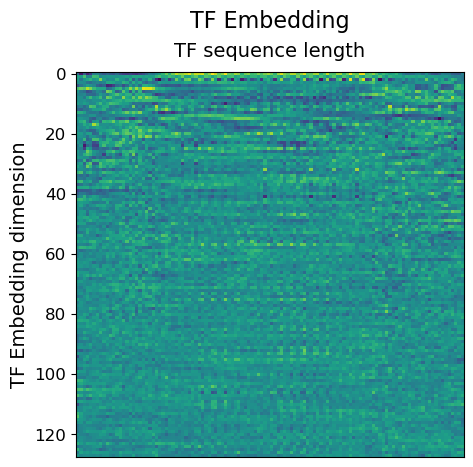

In [87]:
print(f"Edge TF index tensor (shape: {edge_tf_idx_tensor.shape}):")
print(f"First TF index: {edge_tf_idx_tensor[0]}")

print(f"\nTF embedding tensor (shape: {tf_embeddings_tensor.shape}):")
print(f"  - Number of Batches: {tf_embeddings_tensor.shape[0]}")
print(f"  - Largest TF length: {tf_embeddings_tensor.shape[1]}")
print(f"  - Embedding dimension: {tf_embeddings_tensor.shape[2]}")

print(tf_embeddings_tensor[edge_tf_idx_tensor[0], :5, :5])

print(f"\nTF padding mask tensor (shape: {tf_mask_tensor.shape}):")
print(f"  - Number of Batches: {tf_mask_tensor.shape[0]}")
print(f"  - Largest TF length: {tf_mask_tensor.shape[1]}")

mask = tf_mask_tensor[edge_tf_idx_tensor[0]]
num_mask_true_positions = len(torch.where(mask == 1)[0])
num_mask_false_positions = len(torch.where(mask == 0)[0]) - num_mask_true_positions
print(f"\nTF padding mask for the first TF (shape: {mask.shape}):")
print(f"  - {num_mask_true_positions} valid positions (1s)")
print(f"  - {num_mask_false_positions} padded positions (0s)\n")

unmasked_tf_tensor = tf_embeddings_tensor[edge_tf_idx_tensor[0]][mask]


tf_embedding_dict = {
    "TF Embedding": (unmasked_tf_tensor, None)
}
plot_projected_expression(
    tf_embedding_dict, 
    keep_square=False, 
    height=5, 
    xlabel="TF sequence length", 
    ylabel="TF Embedding dimension"
    )


Peak index tensor (shape: torch.Size([9299874])):
First peak index: 3209599

One-hot peak tensor (shape: torch.Size([9032432, 256, 4])):
  - Number of Peaks: 9032432
  - Peak length: 256
  - One-hot encoding dimension: 4



/tmp/ipykernel_1757489/3176541157.py:107: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=12)


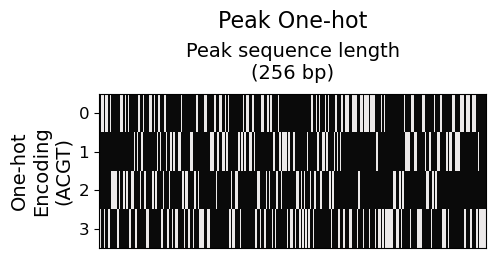

In [68]:
import matplotlib.colors as mcolors
print(f"\nPeak index tensor (shape: {edge_peak_idx_tensor.shape}):")
print(f"First peak index: {edge_peak_idx_tensor[0]}")

print(f"\nOne-hot peak tensor (shape: {one_hot_peaks.shape}):")
print(f"  - Number of Peaks: {one_hot_peaks.shape[0]}")
print(f"  - Peak length: {one_hot_peaks.shape[1]}")
print(f"  - One-hot encoding dimension: {one_hot_peaks.shape[2]}\n")

first_peak_onehot = one_hot_peaks[edge_peak_idx_tensor[0]]
peak_dict = {
    "Peak One-hot": (first_peak_onehot, None),
}

colors = ["#0A0A0A", "#ECE9E9"]

# Create a continuous colormap
custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_2_color", colors
)

plot_projected_expression(
    peak_dict, 
    keep_square=False, 
    height=2,
    xlabel=f"Peak sequence length\n({first_peak_onehot.shape[0]} bp)",
    ylabel="One-hot\nEncoding\n(ACGT)",
    cmap=custom_cmap
    )



### TF Dense Layer

In [112]:
import torch.nn as nn

tf_input = tf_embeddings_tensor[edge_tf_idx_tensor[0]].unsqueeze(0)
m = tf_mask_tensor[edge_tf_idx_tensor[0]].unsqueeze(0)

tf_encoder_linear1 = tf_dna_model.model.tf_encoder[0](tf_input)
tf_encoder_gelu = tf_dna_model.model.tf_encoder[1](tf_encoder_linear1)
tf_encoder_dropout = tf_dna_model.model.tf_encoder[2](tf_encoder_gelu)
tf_encoder_linear2 = tf_dna_model.model.tf_encoder[3](tf_encoder_dropout)

tf_encoder_output_dict = {
    "TF embedding input": (detach(unmask(tf_input, m)), None),
    "Linear1 Output": (detach(unmask(tf_encoder_linear1, m)), None),
    "GELU Output": (detach(unmask(tf_encoder_gelu, m)), None),
    "Dropout Output": (detach(unmask(tf_encoder_dropout, m)), None),
    "Linear2 Output": (detach(unmask(tf_encoder_linear2, m)), None),
}
    


/tmp/ipykernel_1757489/2077226389.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=12)
/tmp/ipykernel_1757489/2077226389.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=12)
/tmp/ipykernel_1757489/2077226389.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=12)
/tmp/ipykernel_1757489/2077226389.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=12)
/tmp/ipykernel_1757489/2077226389.py:119: UserWarning: s

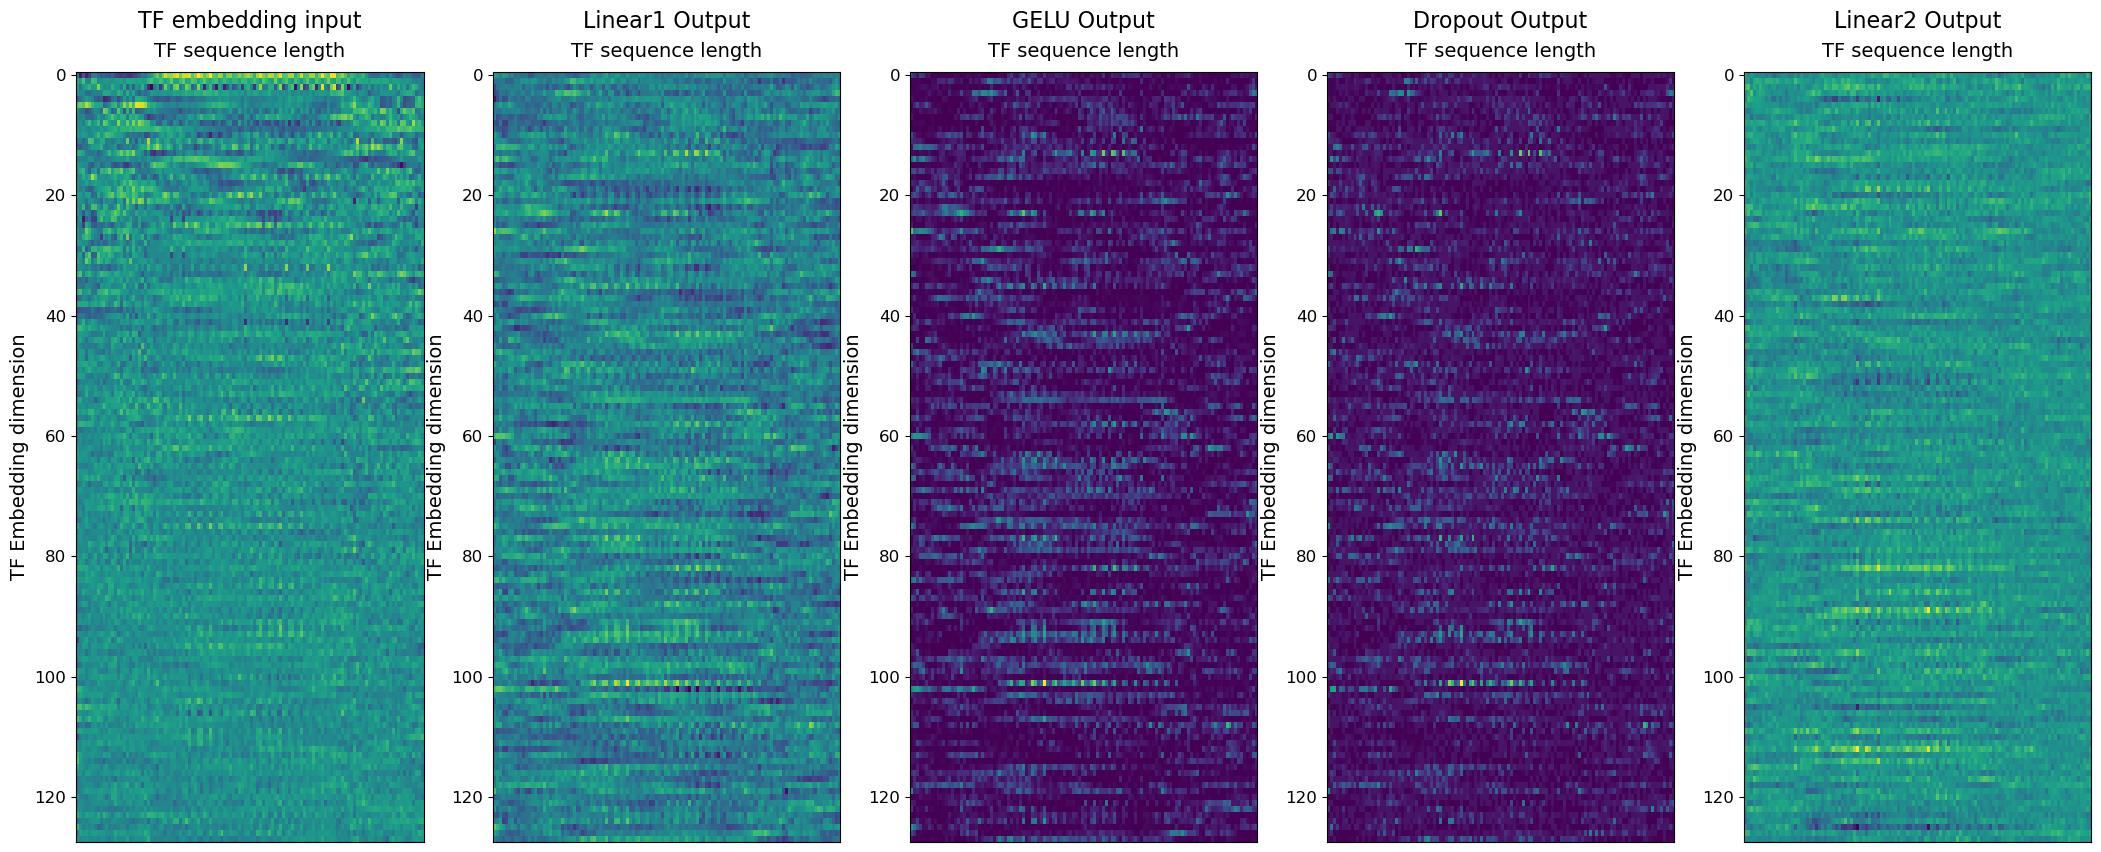

In [115]:
plot_projected_expression(
    tf_encoder_output_dict,
    keep_square=False,
    height=10,
    xlabel="TF sequence length",
    ylabel="TF Embedding dimension"
)

### Peak Encoder

In [128]:
peak_input = one_hot_peaks[edge_peak_idx_tensor[0]].unsqueeze(0).swapaxes(1, 2)
peak_input.to(dtype=torch.float32)
peak_input.shape

torch.Size([1, 4, 256])

In [253]:
layer = tf_dna_model.model.peak_encoder[0]

peak_input = peak_input.to(
    dtype=layer.weight.dtype,
    device=layer.weight.device,
)

peak_layer_dict = {"Peak Input": (peak_input.squeeze(0), None)}
peak_encoder_output = None
for i in range(len(tf_dna_model.model.peak_encoder)):
    layer = tf_dna_model.model.peak_encoder[i]
    
    if i == 0:
        input = peak_input
    else:
        previous_layer_output = peak_layer_dict[f"{layer_type}_{i-1}"][0]
        input = previous_layer_output
        
    layer_output = layer(input)
    layer_type = layer.__class__.__name__
    
    peak_layer_dict[f"{layer_type}_{i}"] = (layer_output, None)
    
    print(f"{layer_type}_{i}")
    print(f"  input shape: {input.shape}")
    print(f"  output shape: {layer_output.shape}")
    
    if i == len(tf_dna_model.model.peak_encoder) - 1:
        peak_encoder_output = layer_output
    
# Detach all tensors in peak_layer_dict
for key in peak_layer_dict:
    peak_layer_dict[key] = (detach(peak_layer_dict[key][0]), peak_layer_dict[key][1])


Conv1d_0
  input shape: torch.Size([1, 4, 256])
  output shape: torch.Size([1, 64, 256])
BatchNorm1d_1
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 256])
GELU_2
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 256])
MaxPool1d_3
  input shape: torch.Size([1, 64, 256])
  output shape: torch.Size([1, 64, 64])
Conv1d_4
  input shape: torch.Size([1, 64, 64])
  output shape: torch.Size([1, 128, 64])
BatchNorm1d_5
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 64])
GELU_6
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 64])
MaxPool1d_7
  input shape: torch.Size([1, 128, 64])
  output shape: torch.Size([1, 128, 16])
Conv1d_8
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16])
BatchNorm1d_9
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16])
GELU_10
  input shape: torch.Size([1, 128, 16])
  output shape: torch.Size([1, 128, 16

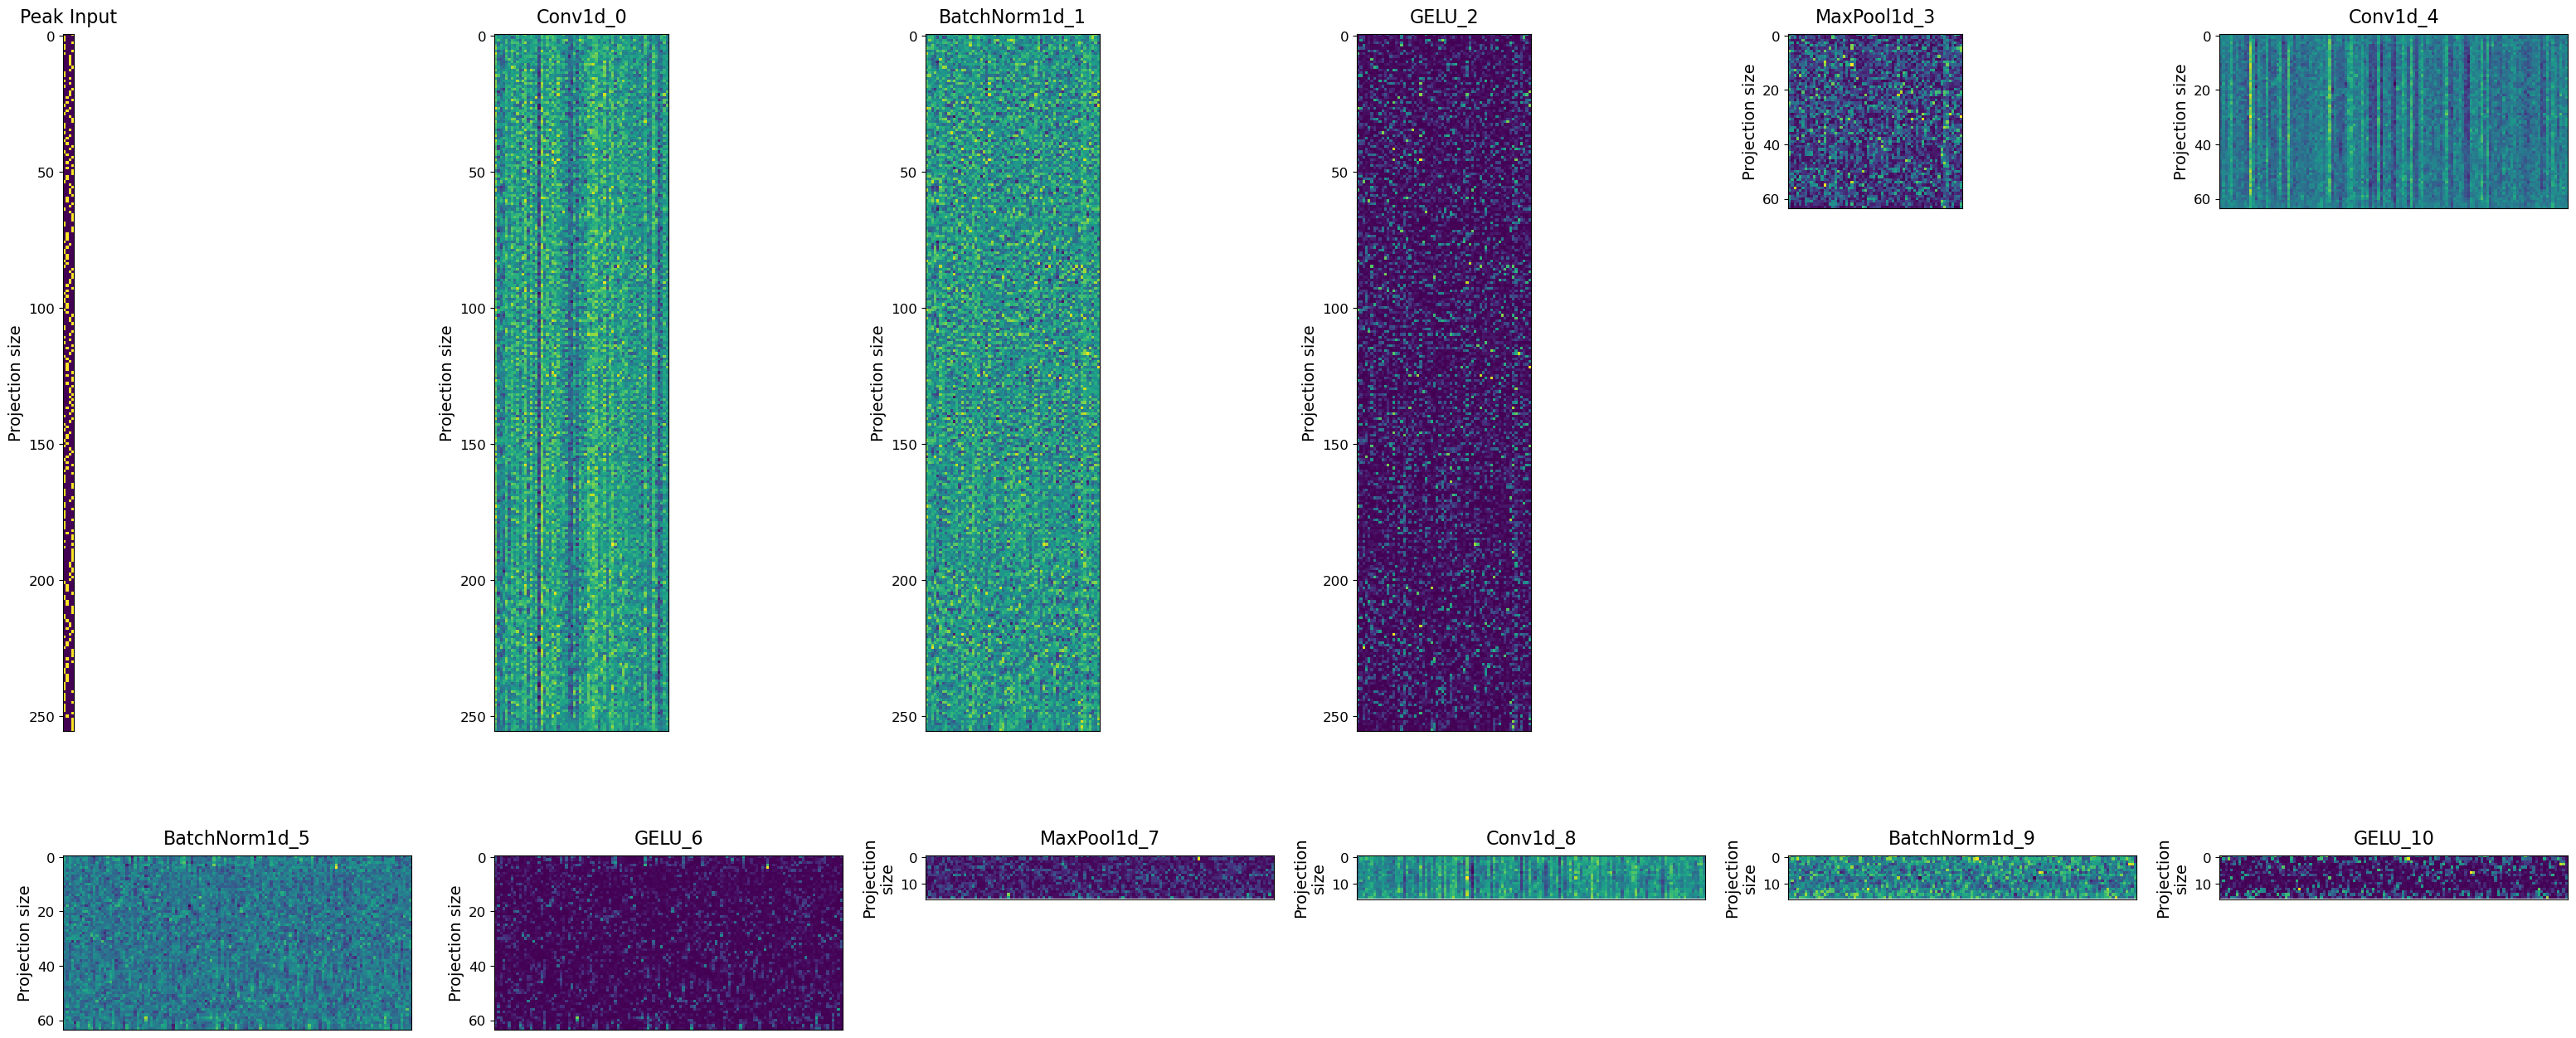

In [254]:

plot_projected_expression(
    peak_layer_dict,
    keep_square=False,
    height=14,
    ncols=6
)

### Cross Attention

In [260]:
tf_cross_input = tf_encoder_linear2
peak_cross_input = peak_encoder_output.transpose(1, 2)

peak_mask = torch.ones(
    peak_cross_input.shape[:2],
    dtype=torch.bool,
    device=peak_cross_input.device,
)

In [256]:
tf_dna_model.model.cross_attn.layers[0][1][0]

RMSNorm((128,), eps=None, elementwise_affine=True)

In [261]:
import torch

cross_attn = tf_dna_model.model.cross_attn
cross_layer_dict = {}
handles = []

def snapshot(output):
    """Store detached copies, preserving tuples/lists/dictionaries."""
    if isinstance(output, torch.Tensor):
        return output.detach().clone()
    if isinstance(output, tuple):
        return tuple(snapshot(value) for value in output)
    if isinstance(output, list):
        return [snapshot(value) for value in output]
    if isinstance(output, dict):
        return {key: snapshot(value) for key, value in output.items()}
    return output


def make_hook(name):
    def hook(module, inputs, output):
        cross_layer_dict[name] = snapshot(output)
    return hook


# Register hooks on each layer and all modules inside it.
for layer_num, layer in enumerate(cross_attn.layers):
    for module_name, module in layer.named_modules():
        name = f"CrossAttention_{layer_num}"
        if module_name:
            name += f"_{module_name.replace('.', '_')}"

        handles.append(
            module.register_forward_hook(make_hook(name))
        )

try:
    with torch.no_grad():
        # Use the same forward call and arguments as your normal execution.
        output = cross_attn(
            tf_cross_input,
            peak_cross_input,
            m,
            peak_mask,
        )
finally:
    # Remove hooks even if the forward pass raises an error.
    for handle in handles:
        handle.remove()

In [262]:
for name, output in cross_layer_dict.items():
    if isinstance(output, torch.Tensor):
        print(f"{name}: {output.shape}")
    elif isinstance(output, tuple):
        print(f"{name}: {[o.shape if isinstance(o, torch.Tensor) else type(o) for o in output]}")
    else:
        print(f"{name}: {type(output)}")

CrossAttention_0_0_norm: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_norm: torch.Size([1, 16, 128])
CrossAttention_0_0_to_qk: torch.Size([1, 5588, 128])
CrossAttention_0_0_to_v: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_to_qk: torch.Size([1, 16, 128])
CrossAttention_0_0_context_to_v: torch.Size([1, 16, 128])
CrossAttention_0_0_dropout: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_context_dropout: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_talking_heads: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_context_talking_heads: torch.Size([1, 4, 5588, 16])
CrossAttention_0_0_to_out: torch.Size([1, 5588, 128])
CrossAttention_0_0_context_to_out: torch.Size([1, 16, 128])
CrossAttention_0_0: [torch.Size([1, 5588, 128]), torch.Size([1, 16, 128])]
CrossAttention_0_1_0: torch.Size([1, 5588, 128])
CrossAttention_0_1_1: torch.Size([1, 5588, 512])
CrossAttention_0_1_2: torch.Size([1, 5588, 512])
CrossAttention_0_1_3: torch.Size([1, 5588, 128])
CrossAttention_0_1: torch.S

In [263]:
def make_cross_attention_heatmaps(
    outputs,
    tf_mask,
    peak_mask,
    batch_index=0,
):
    heatmaps = {}

    # Select masks for one batch item.
    tf_valid = tf_mask[batch_index].detach().cpu().bool()
    peak_valid = peak_mask[batch_index].detach().cpu().bool()

    def add_output(name, output):
        # Handle modules returning multiple outputs.
        if isinstance(output, (tuple, list)):
            for index, value in enumerate(output):
                add_output(f"{name}_output_{index}", value)
            return

        if not isinstance(output, torch.Tensor):
            return

        tensor = output.detach().float().cpu()

        # Token features: (batch, tokens, features)
        if tensor.ndim == 3:
            matrix = tensor[batch_index]

            # Infer the token type from its length.
            # This works for your distinct TF/peak lengths: 5588 and 16.
            if matrix.shape[0] == len(tf_valid):
                matrix = matrix[tf_valid]
            elif matrix.shape[0] == len(peak_valid):
                matrix = matrix[peak_valid]
            else:
                raise ValueError(
                    f"{name}: cannot identify token dimension "
                    f"for shape {tuple(tensor.shape)}"
                )

            if matrix.shape[0] > 0:
                heatmaps[name] = (matrix.numpy(), None)

        # Attention: (batch, heads, TF tokens, peak tokens)
        elif tensor.ndim == 4:
            if tensor.shape[2:] != (len(tf_valid), len(peak_valid)):
                raise ValueError(
                    f"{name}: unexpected attention shape "
                    f"{tuple(tensor.shape)}"
                )

            attention = tensor[batch_index]
            attention = attention[:, tf_valid, :]
            attention = attention[:, :, peak_valid]

            for head_index, matrix in enumerate(attention):
                if all(size > 0 for size in matrix.shape):
                    heatmaps[f"{name}_head_{head_index}"] = (
                        matrix.numpy(),
                        None,
                    )

    for name, output in outputs.items():
        add_output(name, output)

    return heatmaps

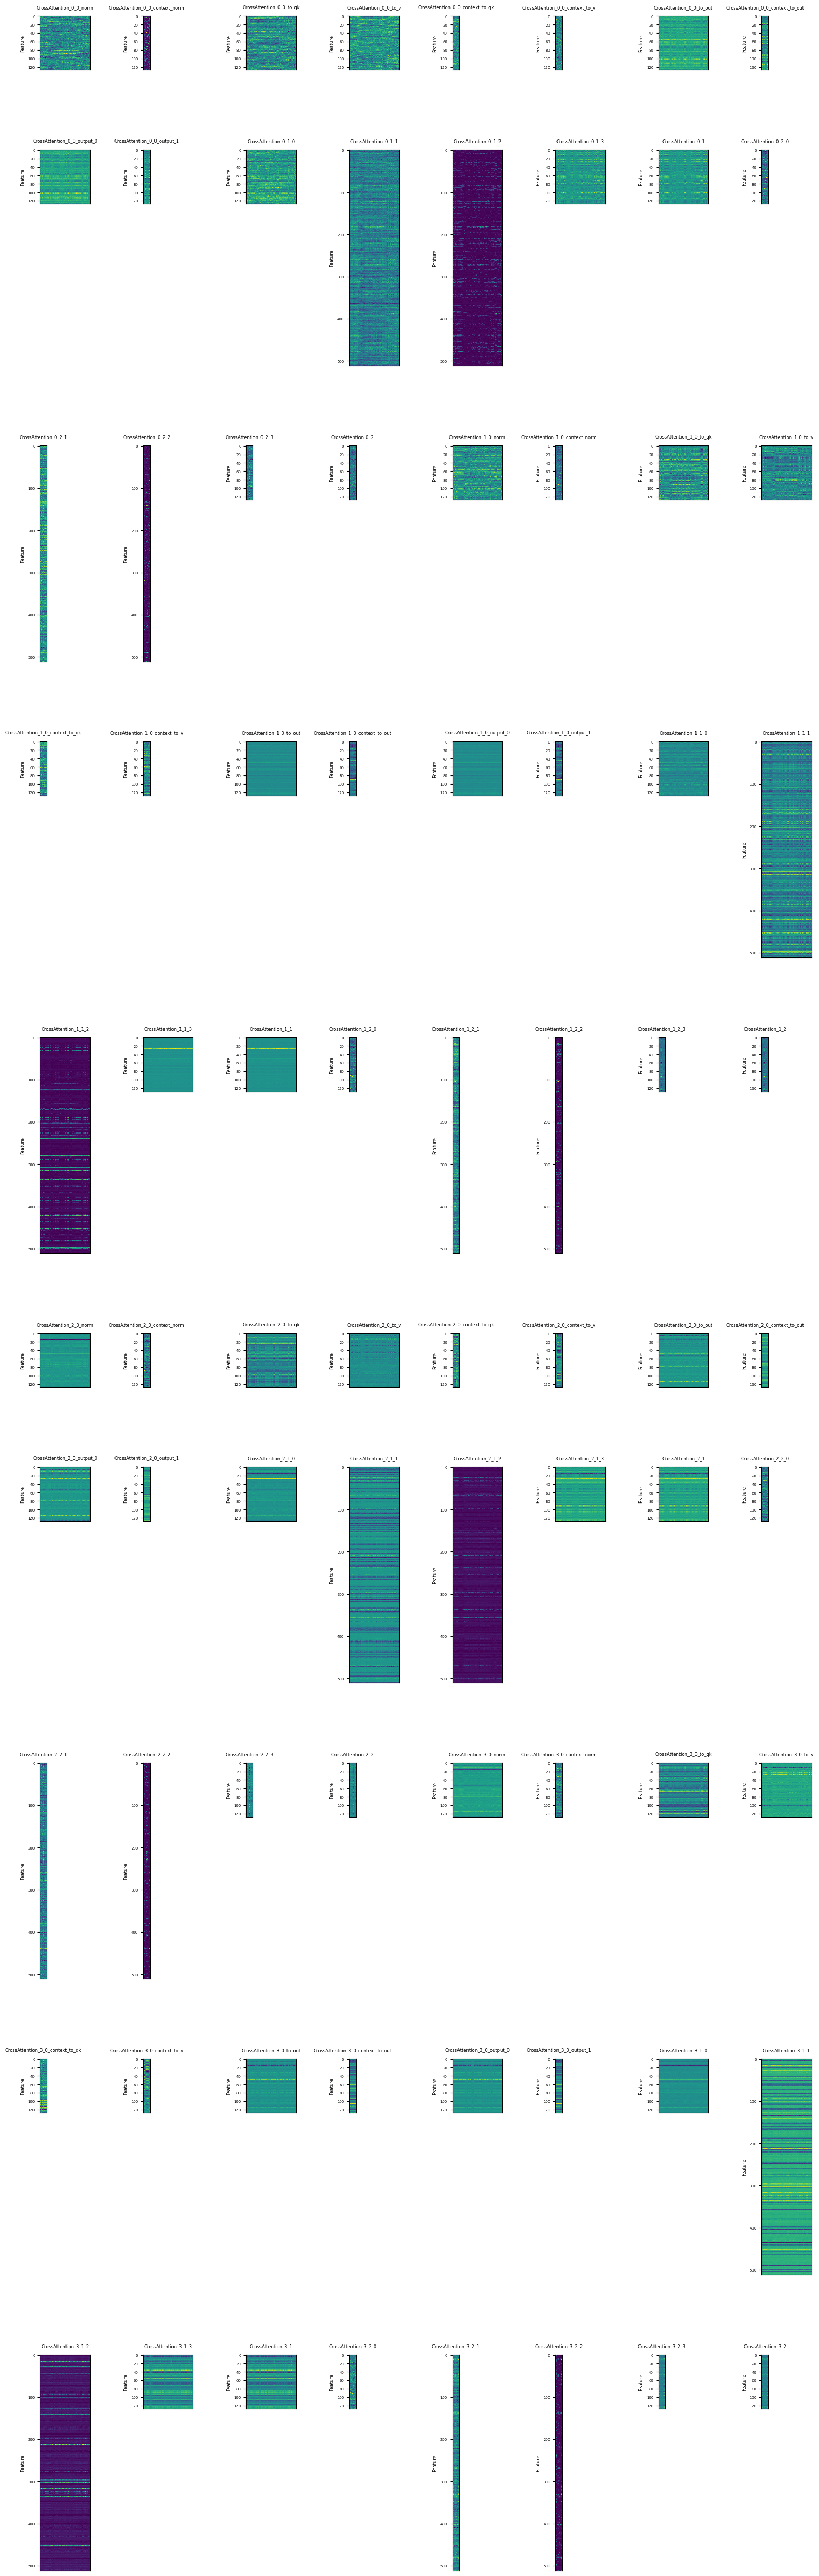

In [279]:
selected = {
    name: output
    for name, output in cross_layer_dict.items()
    if name.startswith("CrossAttention_")
}

heatmaps = make_cross_attention_heatmaps(
    selected,
    tf_mask=m,
    peak_mask=peak_mask,
)

# Plot feature outputs separately from attention matrices.
feature_heatmaps = {
    name: value
    for name, value in heatmaps.items()
    if "_head_" not in name
}

plot_projected_expression(
    feature_heatmaps,
    ncols=8,
    height=50,
    xlabel=None,
    ylabel="Feature",
)